In [1]:
import json
import os
import subprocess

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

In [2]:
root_path = "../"

trizod_filename = os.path.join(root_path, "datasets/cleaned_trizod_dataset.csv")
trizod_df = pd.read_csv(
    trizod_filename,
    index_col="label",
    converters={"gscores": lambda x: np.array(json.loads(x), dtype=float)},
)
# df_train = trizod_df[~trizod_df["is_test"]]
df_test = trizod_df[trizod_df["is_test"]]

In [3]:
filename = "test7.csv"

if not os.path.exists(filename):
    fasta_filename = "test.fasta"
    with open(fasta_filename, "w") as f:
        for label, row in df_test.iterrows():
            f.write(f">{label}\n{row['sequence']}\n")

    subprocess.run(
        [
            "adopt2g-predict",
            "--input",
            fasta_filename,
            "--out",
            filename,
            "--save-member-gscores",
            # "--ensemble-id",
            # "seed883_n5",
        ],
        check=True,
    )
    os.remove(fasta_filename)
df_inferred = pd.read_csv(
    filename,
    index_col="label",
    converters={
        "gscores": lambda x: np.array(json.loads(x), dtype=float),
        "gscores_lower": lambda x: np.array(json.loads(x), dtype=float),
        "gscores_upper": lambda x: np.array(json.loads(x), dtype=float),
        "member_gscores": lambda x: np.array(json.loads(x), dtype=float),
    },
)
df_inferred

2026-01-13 09:23:48 [INFO] adopt2g.inference: Loading ensemble from /home/michele/workdir/ADOPT2g/models/seed883_n7/manifest.json...
2026-01-13 09:23:48 [INFO] adopt2g.inference:   Ensemble ID: seed883_n7
2026-01-13 09:23:48 [INFO] adopt2g.inference:   Ensemble size: 7
2026-01-13 09:23:48 [INFO] adopt2g.inference:   Calibration factor: 4.6228
2026-01-13 09:23:48 [INFO] adopt2g.inference:   Loading ESM model to cuda...
2026-01-13 09:23:49 [WARNING] adopt2g.embeddings: Flash Attention 2 not available (libcudart.so.12: cannot open shared object file: No such file or directory), falling back to sdpa attention


Some weights of EsmModel were not initialized from the model checkpoint at facebook/esm2_t33_650M_UR50D and are newly initialized: ['pooler.dense.bias', 'pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.
/home/michele/miniforge3/envs/adopt2g/lib/python3.12/site-packages/torch/cuda/__init__.py:283: UserWarning: 
    Found GPU0 NVIDIA GB10 which is of cuda capability 12.1.
    Minimum and Maximum cuda capability supported by this version of PyTorch is
    (8.0) - (12.0)
    
  warnings.warn(


2026-01-13 09:23:49 [INFO] adopt2g.inference:   Loading 7 ST models...
2026-01-13 09:23:49 [INFO] sentence_transformers.SentenceTransformer: Use pytorch device_name: cuda:0
2026-01-13 09:23:49 [INFO] sentence_transformers.SentenceTransformer: Load pretrained SentenceTransformer: /home/michele/workdir/ADOPT2g/models/seed883_n7/member_0/st
2026-01-13 09:23:49 [INFO] sentence_transformers.SentenceTransformer: Use pytorch device_name: cuda:0
2026-01-13 09:23:49 [INFO] sentence_transformers.SentenceTransformer: Load pretrained SentenceTransformer: /home/michele/workdir/ADOPT2g/models/seed883_n7/member_1/st
2026-01-13 09:23:50 [INFO] sentence_transformers.SentenceTransformer: Use pytorch device_name: cuda:0
2026-01-13 09:23:50 [INFO] sentence_transformers.SentenceTransformer: Load pretrained SentenceTransformer: /home/michele/workdir/ADOPT2g/models/seed883_n7/member_2/st
2026-01-13 09:23:50 [INFO] sentence_transformers.SentenceTransformer: Use pytorch device_name: cuda:0
2026-01-13 09:23:50 

Predicting: 100%|██████████| 160/160 [00:00<00:00, 2064888.12it/s]

Batches: 100%|██████████| 5/5 [00:00<00:00, 16.02it/s]

Batches: 100%|██████████| 5/5 [00:00<00:00, 33.18it/s]

Batches: 100%|██████████| 5/5 [00:00<00:00, 33.53it/s]

Batches: 100%|██████████| 5/5 [00:00<00:00, 32.80it/s]

Batches: 100%|██████████| 5/5 [00:00<00:00, 33.49it/s]

Batches: 100%|██████████| 5/5 [00:00<00:00, 32.91it/s]

100%|██████████| 1/1 [00:04<00:00,  4.57s/it]


2026-01-13 09:23:55 [INFO] adopt2g.scripts.predict: Combining chunks...
2026-01-13 09:23:55 [INFO] adopt2g.scripts.predict: Results saved to test7.csv
2026-01-13 09:23:55 [INFO] adopt2g.scripts.predict: Columns: label, sequence, mean_gscore, mean_gscore_lower, mean_gscore_upper, gscores, gscores_lower, gscores_upper, member_gscores
2026-01-13 09:23:55 [INFO] adopt2g.scripts.predict:   - mean_gscore_lower/upper: calibrated confidence bounds for mean_gscore (asymmetric)
2026-01-13 09:23:55 [INFO] adopt2g.scripts.predict:   - gscores_lower/upper: calibrated per-residue confidence bounds (JSON arrays, asymmetric)
2026-01-13 09:23:55 [INFO] adopt2g.scripts.predict:   - member_gscores: per-residue gscores for each ensemble member (JSON 2D array)
2026-01-13 09:23:55 [INFO] adopt2g.scripts.predict: (Use json.loads() to parse JSON array columns)


,sequence,mean_gscore,mean_gscore_lower,mean_gscore_upper,gscores,gscores_lower,gscores_upper,member_gscores
label,,,,,,,,
1474_1_1_1,DYAKCVFPFIYGGKKYETCTKIGSMWMSWCSLSPNYDKDRAWKYC,0.110856,0.070861,0.169310,"[0.21816924312317365, 0.24780535225298048, 0.2...","[0.08494710334281272, 0.16398024910404718, 0.1...","[0.4561674946423043, 0.356334658496391, 0.4835...","[[0.1979091073368183, 0.26702572083094006, 0.3..."
1757_1_1_1,SELEEDFAKILMLKEERIKELEKRLSEKEEEIQELKRKL,0.127249,0.069201,0.222358,"[0.2566456398350909, 0.2496301234656827, 0.246...","[0.10932483007763893, 0.046378205994811086, 0....","[0.4924322185935058, 0.694924132784345, 0.5185...","[[0.2762021918385483, 0.2104415994810358, 0.25..."
2384_1_1_1,XKPAACRCSRQDPKNRVNCGFPGITSDQCFTSGCCFDSQVPGVPWC...,0.149549,0.107909,0.203590,"[nan, 0.4987554575873048, 0.5517850723517317, ...","[nan, 0.12581531755016742, 0.1030244283262171,...","[nan, 0.8731066714994528, 0.9294404038127071, ...","[[nan, 0.47635127631891044, 0.5371020863865634..."
4136_1_1_1,MNPYIYLGGAILAEVIGTTLMKFSEGFTRLWPSVGTIICYCASFWL...,0.105579,0.077908,0.141569,"[0.24908175189735487, 0.20386598549236373, 0.1...","[0.12054230544225221, 0.05033063259747688, 0.0...","[0.4452883047574535, 0.5530225481821641, 0.364...","[[0.2344066457818812, 0.18213440280618404, 0.1..."
4272_1_1_1,MSATAATAPPAAPAGEGGPPAPPPNLTSNRRLQQTQAQVDEVVDIM...,0.612512,0.213904,0.901794,"[0.7236025364558359, 0.7316342000863527, 0.730...","[0.3175320693690182, 0.37524847010976525, 0.36...","[0.9364014209523385, 0.9252299570920387, 0.927...","[[0.7854731824873945, 0.6984323069261458, 0.74..."
...,...,...,...,...,...,...,...,...
52866_1_1_1,GHMHLQDSQQEISSMQMKLMEMKDLENHNSQLNWCSSPHSILVNGA...,0.698432,0.263632,0.937430,"[0.4147210557680346, 0.4831911509218933, 0.537...","[0.20737519083591816, 0.1758209177336658, 0.14...","[0.6575384268506705, 0.8037905871912979, 0.885...","[[0.49717906130353545, 0.46986992399750666, 0...."
53024_2_1_1,MRWYPWLRPDFEKLVASYQAGRGHHALLIQALPGMGDDALIYALSR...,0.115932,0.055457,0.226537,"[0.3820261617180773, 0.4303867404899131, 0.234...","[0.05098814552771514, 0.16000335352396436, 0.0...","[0.8768454440200762, 0.7498206999089312, 0.461...","[[0.31795547296854265, 0.46150212921468203, 0...."
53287_1_1_1,MAHHHHHHMTLTFNIKVIEAKDLPKVDTFGKVDPYVQIQLGNEKCK...,0.089819,0.056805,0.139187,"[0.6463486089654296, 0.3957178317228787, 0.535...","[0.15662018336345096, 0.16158466261689475, 0.1...","[0.9473810466522863, 0.6900371464958261, 0.888...","[[0.5714676871674993, 0.413181143782958, 0.519..."


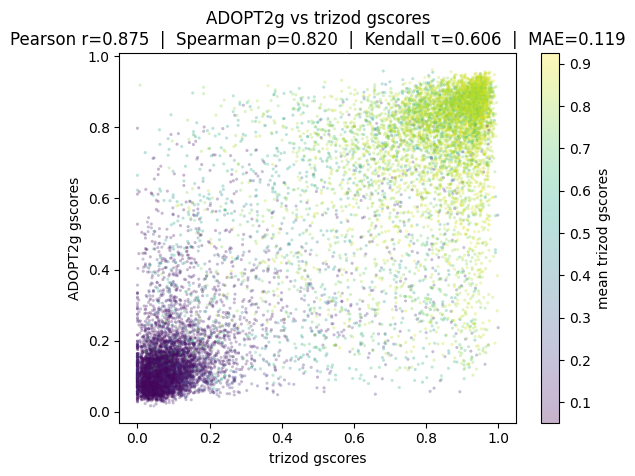

Summary of metrics for each member and mean prediction:

member_id  pearson_r  spearman_rho  kendall_tau    mae
     mean     0.8752        0.8200       0.6062 0.1192
        0     0.8595        0.8037       0.5873 0.1263
        1     0.8571        0.8066       0.5930 0.1247
        2     0.8625        0.8063       0.5914 0.1244
        3     0.8447        0.8005       0.5866 0.1303
        4     0.8593        0.8039       0.5887 0.1243
        5     0.8584        0.8023       0.5850 0.1266
        6     0.8768        0.8142       0.6007 0.1192

  Members with higher Pearson r than mean: [6]


In [4]:
from scipy.stats import kendalltau, pearsonr, spearmanr

member_metrics = []
mean_trizod_gscores = np.repeat(df_test["gscores"].apply(np.nanmean).values, df_test["gscores"].apply(len).values)
trizod_gscores = np.concatenate(df_test["gscores"].values)
adopt2_gscores = np.concatenate(df_inferred["gscores"].values)
mask = np.isfinite(trizod_gscores) & np.isfinite(adopt2_gscores)

# Compute correlation metrics
pearson_r, _ = pearsonr(trizod_gscores[mask], adopt2_gscores[mask])
spearman_rho, _ = spearmanr(trizod_gscores[mask], adopt2_gscores[mask])
kendall_tau, _ = kendalltau(trizod_gscores[mask], adopt2_gscores[mask])

# Also compute MAE for prediction accuracy
mae = np.mean(np.abs(trizod_gscores[mask] - adopt2_gscores[mask]))

member_metrics.append(
    {
        "member_id": "mean",
        "pearson_r": pearson_r,
        "spearman_rho": spearman_rho,
        "kendall_tau": kendall_tau,
        "mae": mae,
    }
)

plt.scatter(trizod_gscores, adopt2_gscores, alpha=0.3, s=5, lw=0, c=mean_trizod_gscores)
plt.xlabel("trizod gscores")
plt.ylabel("ADOPT2g gscores")
plt.title(
    f"ADOPT2g vs trizod gscores\nPearson r={pearson_r:.3f}  |  Spearman ρ={spearman_rho:.3f}  |  Kendall τ={kendall_tau:.3f}  |  MAE={mae:.3f}",
)
plt.colorbar(label="mean trizod gscores")
plt.show()

n_members = len(df_inferred["member_gscores"].iloc[0]) if "member_gscores" in df_inferred.columns else 0

# Prepare to collect summary stats for each member
for m in range(n_members):
    mean_trizod_gscores = np.repeat(df_test["gscores"].apply(np.nanmean).values, df_test["gscores"].apply(len).values)
    trizod_gscores = np.concatenate(df_test["gscores"].values)
    # Select the gscores for the current member 'm' from the 2D list in each row, then flatten
    adopt2_gscores = np.concatenate([gscores[m] for gscores in df_inferred["member_gscores"].values])
    mask = np.isfinite(trizod_gscores) & np.isfinite(adopt2_gscores)

    # Compute correlation metrics
    pearson_r, _ = pearsonr(trizod_gscores[mask], adopt2_gscores[mask])
    spearman_rho, _ = spearmanr(trizod_gscores[mask], adopt2_gscores[mask])
    kendall_tau, _ = kendalltau(trizod_gscores[mask], adopt2_gscores[mask])

    # Also compute MAE for prediction accuracy
    mae = np.mean(np.abs(trizod_gscores[mask] - adopt2_gscores[mask]))

    member_metrics.append(
        {
            "member_id": m,
            "pearson_r": pearson_r,
            "spearman_rho": spearman_rho,
            "kendall_tau": kendall_tau,
            "mae": mae,
        }
    )

    # plt.scatter(trizod_gscores, adopt2_gscores, alpha=0.3, s=5, lw=0, c=mean_trizod_gscores)
    # plt.xlabel("trizod gscores")
    # plt.ylabel("ADOPT2g gscores")
    # plt.title(
    #     f"m={m}: ADOPT2g vs trizod gscores\nPearson r={pearson_r:.3f}  |  Spearman ρ={spearman_rho:.3f}  |  Kendall τ={kendall_tau:.3f}  |  MAE={mae:.3f}",
    # )
    # plt.colorbar(label="mean trizod gscores")
    # plt.show()

if n_members > 0:
    summary_df = pd.DataFrame(member_metrics)
    print("Summary of metrics for each member and mean prediction:\n")
    print(summary_df.to_string(index=False, float_format="%.4f"))

    # Check if any member has better metric than mean
    # Lower MAE is better, higher correlation is better
    mae_mean = summary_df["mae"][summary_df["member_id"] == "mean"].values[0]
    pearson_r_mean = summary_df["pearson_r"][summary_df["member_id"] == "mean"].values[0]
    spearman_rho_mean = summary_df["spearman_rho"][summary_df["member_id"] == "mean"].values[0]
    kendall_tau_mean = summary_df["kendall_tau"][summary_df["member_id"] == "mean"].values[0]

    better_mae_members = summary_df[summary_df["mae"] < mae_mean]["member_id"].tolist()
    better_pearson_members = summary_df[summary_df["pearson_r"] > pearson_r_mean]["member_id"].tolist()
    better_spearman_members = summary_df[summary_df["spearman_rho"] > spearman_rho_mean]["member_id"].tolist()
    better_kendall_members = summary_df[summary_df["kendall_tau"] > kendall_tau_mean]["member_id"].tolist()

    if better_mae_members or better_pearson_members or better_spearman_members or better_kendall_members:
        print("\nWARNING: Some members have better metrics than the mean prediction:")
        if better_mae_members:
            print(f"  Members with lower MAE than mean: {better_mae_members}")
        if better_pearson_members:
            print(f"  Members with higher Pearson r than mean: {better_pearson_members}")
        if better_spearman_members:
            print(f"  Members with higher Spearman rho than mean: {better_spearman_members}")
        if better_kendall_members:
            print(f"  Members with higher Kendall tau than mean: {better_kendall_members}")
    else:
        print("No members have better metrics than the mean prediction.")


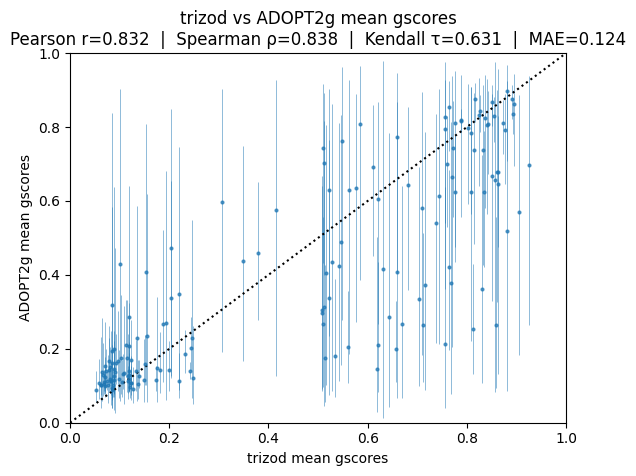

In [5]:
# Compute correlation metrics for mean gscores
pearson_r_mean, _ = pearsonr(df_test["mean_gscore"], df_inferred["mean_gscore"])
spearman_rho_mean, _ = spearmanr(df_test["mean_gscore"], df_inferred["mean_gscore"])
kendall_tau_mean, _ = kendalltau(df_test["mean_gscore"], df_inferred["mean_gscore"])
mae_mean = np.mean(np.abs(df_test["mean_gscore"].values - df_inferred["mean_gscore"].values))

plt.errorbar(
    df_test["mean_gscore"],
    df_inferred["mean_gscore"],
    yerr=[
        df_inferred["mean_gscore"] - df_inferred["mean_gscore_lower"],
        df_inferred["mean_gscore_upper"] - df_inferred["mean_gscore"],
    ],
    fmt="o",
    markersize=2,
    elinewidth=0.5,
    alpha=0.7,
    capsize=0,
)
plt.xlabel("trizod mean gscores")
plt.ylabel("ADOPT2g mean gscores")
plt.title(
    f"trizod vs ADOPT2g mean gscores\nPearson r={pearson_r_mean:.3f}  |  Spearman ρ={spearman_rho_mean:.3f}  |  Kendall τ={kendall_tau_mean:.3f}  |  MAE={mae_mean:.3f}",
)
plt.axline((0.5, 0.5), slope=1, color="k", ls=":")
plt.xlim(0, 1)
plt.ylim(0, 1)
plt.show()


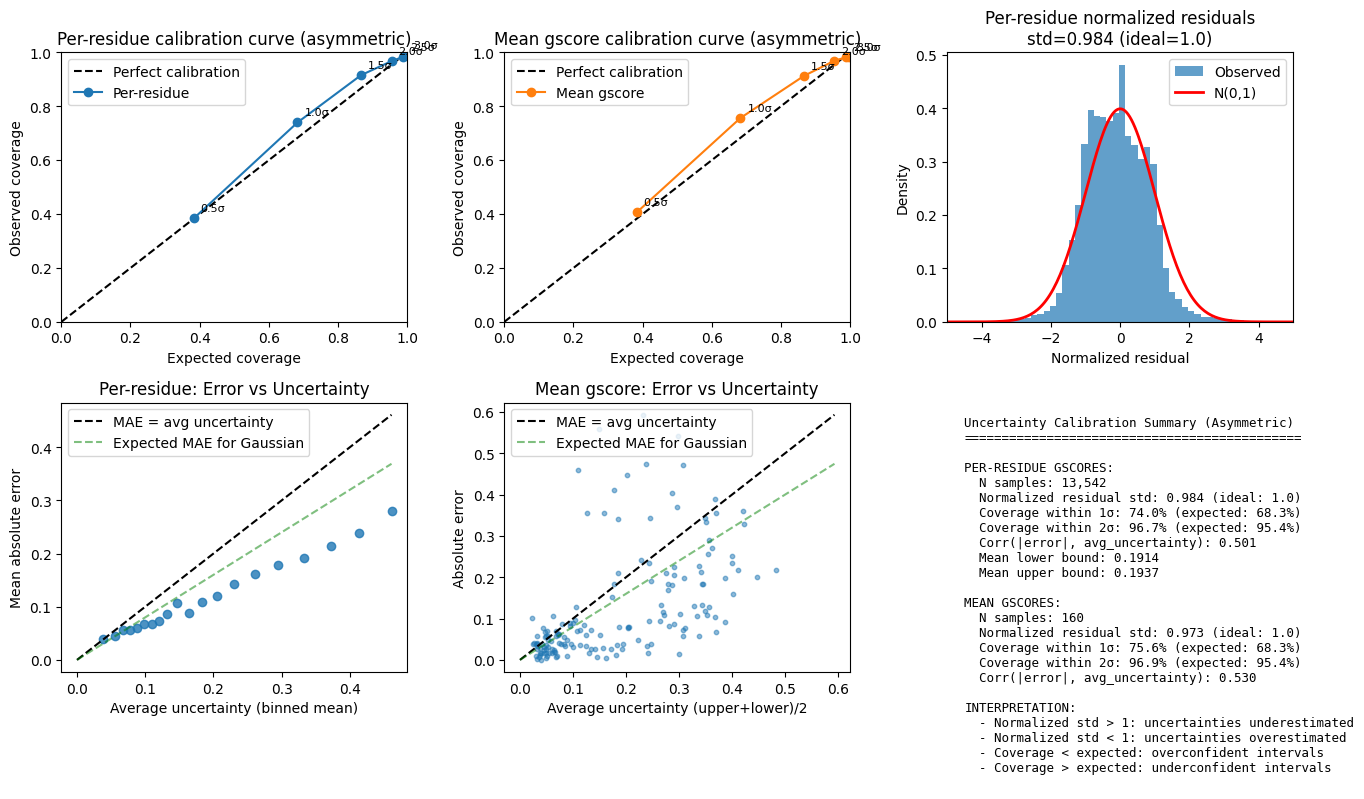

In [6]:
# Uncertainty calibration analysis with asymmetric intervals
# For well-calibrated uncertainties, ~68% of true values should fall within the 1σ interval, ~95% within 2σ

# --- Per-residue uncertainty calibration (asymmetric) ---
trizod_gscores = np.concatenate(df_test["gscores"].values)
pred_gscores = np.concatenate(df_inferred["gscores"].values)
pred_gscores_lower = np.concatenate(df_inferred["gscores_lower"].values)
pred_gscores_upper = np.concatenate(df_inferred["gscores_upper"].values)

# Compute asymmetric uncertainties (distance from prediction to bounds)
pred_err_lower = pred_gscores - pred_gscores_lower  # positive: how far below pred the lower bound is
pred_err_upper = pred_gscores_upper - pred_gscores  # positive: how far above pred the upper bound is

# Mask for valid values
mask = (
    np.isfinite(trizod_gscores)
    & np.isfinite(pred_gscores)
    & np.isfinite(pred_gscores_lower)
    & np.isfinite(pred_gscores_upper)
    & (pred_err_lower > 0)
    & (pred_err_upper > 0)
)
true_vals = trizod_gscores[mask]
pred_vals = pred_gscores[mask]
err_lower = pred_err_lower[mask]
err_upper = pred_err_upper[mask]

# Compute z-scores using asymmetric bounds
# Use upper bound for positive residuals (true > pred), lower bound for negative residuals
residuals = true_vals - pred_vals
z_scores = np.where(
    residuals >= 0,
    residuals / err_upper,  # true above pred: normalize by upper uncertainty
    residuals / err_lower,  # true below pred: normalize by lower uncertainty (gives negative z)
)

# For binned analysis, use average uncertainty width
avg_err = (err_lower + err_upper) / 2

# Calibration: fraction of points within n-scaled intervals
n_sigmas = np.array([0.5, 1, 1.5, 2, 2.5, 3])
from scipy.stats import norm

expected_coverage = np.array([norm.cdf(n) - norm.cdf(-n) for n in n_sigmas])

# For asymmetric intervals: check if true is within [pred - n*err_lower, pred + n*err_upper]
observed_coverage_residue = np.array(
    [np.mean((true_vals >= pred_vals - n * err_lower) & (true_vals <= pred_vals + n * err_upper)) for n in n_sigmas],
)

# --- Mean gscore uncertainty calibration (asymmetric) ---
true_mean = df_test["mean_gscore"].values
pred_mean = df_inferred["mean_gscore"].values
pred_mean_lower = df_inferred["mean_gscore_lower"].values
pred_mean_upper = df_inferred["mean_gscore_upper"].values

# Asymmetric uncertainties for mean
mean_err_lower = pred_mean - pred_mean_lower
mean_err_upper = pred_mean_upper - pred_mean

mask_mean = (
    np.isfinite(true_mean)
    & np.isfinite(pred_mean)
    & np.isfinite(pred_mean_lower)
    & np.isfinite(pred_mean_upper)
    & (mean_err_lower > 0)
    & (mean_err_upper > 0)
)
residuals_mean = true_mean[mask_mean] - pred_mean[mask_mean]
z_scores_mean = np.where(
    residuals_mean >= 0,
    residuals_mean / mean_err_upper[mask_mean],
    residuals_mean / mean_err_lower[mask_mean],
)

observed_coverage_mean = np.array(
    [
        np.mean(
            (true_mean[mask_mean] >= pred_mean[mask_mean] - n * mean_err_lower[mask_mean])
            & (true_mean[mask_mean] <= pred_mean[mask_mean] + n * mean_err_upper[mask_mean]),
        )
        for n in n_sigmas
    ],
)

# --- Plotting ---
fig, axes = plt.subplots(2, 3, figsize=(14, 8))

# 1. Calibration curve - Per-residue
ax = axes[0, 0]
ax.plot([0, 1], [0, 1], "k--", label="Perfect calibration")
ax.plot(expected_coverage, observed_coverage_residue, "o-", color="tab:blue", label="Per-residue")
ax.set_xlabel("Expected coverage")
ax.set_ylabel("Observed coverage")
ax.set_title("Per-residue calibration curve (asymmetric)")
ax.legend()
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
for i, n in enumerate(n_sigmas):
    ax.annotate(
        f"{n}σ",
        (expected_coverage[i], observed_coverage_residue[i]),
        textcoords="offset points",
        xytext=(5, 5),
        fontsize=8,
    )

# 2. Calibration curve - Mean gscore
ax = axes[0, 1]
ax.plot([0, 1], [0, 1], "k--", label="Perfect calibration")
ax.plot(expected_coverage, observed_coverage_mean, "o-", color="tab:orange", label="Mean gscore")
ax.set_xlabel("Expected coverage")
ax.set_ylabel("Observed coverage")
ax.set_title("Mean gscore calibration curve (asymmetric)")
ax.legend()
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
for i, n in enumerate(n_sigmas):
    ax.annotate(
        f"{n}σ",
        (expected_coverage[i], observed_coverage_mean[i]),
        textcoords="offset points",
        xytext=(5, 5),
        fontsize=8,
    )

# 3. Z-score histogram - Per-residue (asymmetric)
ax = axes[0, 2]
ax.hist(z_scores, bins=100, density=True, alpha=0.7, label="Observed")
x_range = np.linspace(-5, 5, 200)
ax.plot(x_range, norm.pdf(x_range), "r-", lw=2, label="N(0,1)")
ax.set_xlabel("Normalized residual")
ax.set_ylabel("Density")
ax.set_title(f"Per-residue normalized residuals\nstd={np.std(z_scores):.3f} (ideal=1.0)")
ax.legend()
ax.set_xlim(-5, 5)

# 4. Error vs predicted uncertainty - Per-residue (binned)
ax = axes[1, 0]
abs_errors = np.abs(residuals)
# Bin by average uncertainty
n_bins = 20
err_bins = np.percentile(avg_err, np.linspace(0, 100, n_bins + 1))
bin_centers = []
mean_errors = []
for i in range(n_bins):
    in_bin = (avg_err >= err_bins[i]) & (avg_err < err_bins[i + 1])
    if np.sum(in_bin) > 10:
        bin_centers.append(np.mean(avg_err[in_bin]))
        mean_errors.append(np.mean(abs_errors[in_bin]))
ax.scatter(bin_centers, mean_errors, alpha=0.8)
max_val = max(max(bin_centers), max(mean_errors))
ax.plot([0, max_val], [0, max_val], "k--", label="MAE = avg uncertainty")
ax.plot([0, max_val], [0, max_val * 0.8], "g--", alpha=0.5, label="Expected MAE for Gaussian")
ax.set_xlabel("Average uncertainty (binned mean)")
ax.set_ylabel("Mean absolute error")
ax.set_title("Per-residue: Error vs Uncertainty")
ax.legend()

# 5. Error vs predicted uncertainty - Mean gscore
ax = axes[1, 1]
abs_errors_mean = np.abs(residuals_mean)
avg_err_mean = (mean_err_lower[mask_mean] + mean_err_upper[mask_mean]) / 2
ax.scatter(avg_err_mean, abs_errors_mean, alpha=0.5, s=10)
max_val = max(avg_err_mean.max(), abs_errors_mean.max())
ax.plot([0, max_val], [0, max_val], "k--", label="MAE = avg uncertainty")
ax.plot([0, max_val], [0, max_val * 0.8], "g--", alpha=0.5, label="Expected MAE for Gaussian")
ax.set_xlabel("Average uncertainty (upper+lower)/2")
ax.set_ylabel("Absolute error")
ax.set_title("Mean gscore: Error vs Uncertainty")
ax.legend()

# 6. Summary statistics table
ax = axes[1, 2]
ax.axis("off")
summary_text = f"""Uncertainty Calibration Summary (Asymmetric)
{"=" * 45}

PER-RESIDUE GSCORES:
  N samples: {len(z_scores):,}
  Normalized residual std: {np.std(z_scores):.3f} (ideal: 1.0)
  Coverage within 1σ: {observed_coverage_residue[1] * 100:.1f}% (expected: 68.3%)
  Coverage within 2σ: {observed_coverage_residue[3] * 100:.1f}% (expected: 95.4%)
  Corr(|error|, avg_uncertainty): {np.corrcoef(abs_errors, avg_err)[0, 1]:.3f}
  Mean lower bound: {np.mean(err_lower):.4f}
  Mean upper bound: {np.mean(err_upper):.4f}

MEAN GSCORES:
  N samples: {len(z_scores_mean):,}
  Normalized residual std: {np.std(z_scores_mean):.3f} (ideal: 1.0)
  Coverage within 1σ: {observed_coverage_mean[1] * 100:.1f}% (expected: 68.3%)
  Coverage within 2σ: {observed_coverage_mean[3] * 100:.1f}% (expected: 95.4%)
  Corr(|error|, avg_uncertainty): {np.corrcoef(abs_errors_mean, avg_err_mean)[0, 1]:.3f}

INTERPRETATION:
  - Normalized std > 1: uncertainties underestimated
  - Normalized std < 1: uncertainties overestimated
  - Coverage < expected: overconfident intervals
  - Coverage > expected: underconfident intervals
"""
ax.text(0.05, 0.95, summary_text, transform=ax.transAxes, fontsize=9, verticalalignment="top", fontfamily="monospace")

plt.tight_layout()
plt.show()